# 04. Experimentos de Chunking
Comparamos artigos completos, registros de subdispositivos e janelas com sobreposição sobre o mesmo conjunto de artigos reconstruídos. Preâmbulos, títulos e anexos não entram nesta comparação e permanecem na base estruturada para experimentos próprios.

Alertas do parser são preservados e as métricas são separadas entre artigos com e sem alertas. Nenhuma estratégia é declarada vencedora antes da avaliação da recuperação.

In [10]:
from pathlib import Path
import pandas as pd
import re
import json
import hashlib
from datetime import datetime, timezone

def find_project_root(start: Path) -> Path:
    for base in (start, *start.parents):
        if (base / 'data/processed/legislacao').is_dir():
            return base
    raise FileNotFoundError('Execute o notebook 03: base estruturada não encontrada.')

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
PROCESSED_DIR = PROJECT_ROOT / 'data/processed/legislacao'
CHUNKS_DIR = PROJECT_ROOT / 'data/chunks/legislacao'
REPORT_DIR = PROJECT_ROOT / 'reports/legislacao/chunking'
df_artigos = pd.read_json(PROCESSED_DIR / 'legislacao_artigos_completos.json')
df_dispositivos = pd.read_json(PROCESSED_DIR / 'legislacao_estruturada_contexto.json')
if df_artigos.empty or df_dispositivos.empty:
    raise ValueError('Base vazia. Execute e valide o notebook 03.')
required = {'artigo_id', 'texto_artigo_completo', 'texto_original', 'tem_alerta_parser',
            'caminho_relativo', 'sha256_fonte', 'posicao_inicio', 'posicao_fim'}
if not required.issubset(df_artigos.columns):
    raise ValueError('Base incompatível: reexecute as etapas complementares do notebook 03.')
if not df_artigos['artigo_id'].is_unique:
    raise ValueError('Identificadores de artigo repetidos.')
for caminho_value, group in df_artigos.groupby('caminho_relativo'):
    caminho = str(caminho_value)
    raw_bytes = (PROJECT_ROOT / 'data/raw/legislacao' / caminho).read_bytes()
    if not group['sha256_fonte'].eq(hashlib.sha256(raw_bytes).hexdigest()).all():
        raise ValueError(f'Fonte alterada desde a estruturação: {caminho}')
print(f'• Artigos carregados: {len(df_artigos)}')

• Artigos carregados: 5284


## 1. Unidade de Medida e Rastreabilidade
Se tiktoken e seu vocabulário estiverem disponíveis, usamos cl100k_base como tokenizador de referência, sem presumir que seja o do futuro modelo de embeddings. Caso contrário, executamos uma linha de base explicitamente em caracteres. Caracteres / 4 é apenas uma estimativa e não define limites reais de tokens.

As posições são relativas ao texto normalizado do artigo; para subdispositivos também preservamos posições no original. O contexto é separado do corpo e contabilizado no tamanho final.

In [11]:
TOKENIZER_NAME = 'cl100k_base'
EXPERIMENT_VERSION = "2.0.0"
REFERENCE_INPUT_LIMIT = 8192
encoder = None
tokenizer_error = ''
try:
    import tiktoken
    encoder = tiktoken.get_encoding(TOKENIZER_NAME)
except (ImportError, OSError, ValueError) as e:
    tokenizer_error = str(e)
UNIT = 'tokens' if encoder is not None else 'caracteres'
WINDOW_CONFIGS = [(300, 50), (500, 75)] if encoder is not None else [(1200, 200), (2000, 300)]
print(f'• Unidade das janelas: {UNIT}')
if encoder is None:
    print('• Tokenização real indisponível. Instale tiktoken e disponibilize o vocabulário para comparar janelas em tokens.')

def token_count(text):
    return len(encoder.encode(text, disallowed_special=())) if encoder is not None else None

def make_chunk(article, strategy, text, start, end, part, context=None, source_record=None):
    context = context or article['caminho_hierarquico']
    header = f"[{article['caminho_relativo']} | {context}]"
    full_text = header + '\n' + text
    key = f"{EXPERIMENT_VERSION}|{TOKENIZER_NAME if encoder is not None else 'caracteres'}|{strategy}|{article['artigo_id']}|{part}|{start}|{end}|{article['sha256_fonte']}"
    return {
        'chunk_id': hashlib.sha256(key.encode('utf-8')).hexdigest(),
        'estrategia': strategy, 'artigo_id': article['artigo_id'],
        'artigo_ref': article['identificador_artigo'], 'caminho_relativo': article['caminho_relativo'],
        'sha256_fonte': article['sha256_fonte'], 'status_declarado': article['status_declarado'],
        'source': article['source'], 'date': article['date'], 'retrieved': article['retrieved'],
        'tem_alerta_parser': bool(article['tem_alerta_parser']),
        'contexto': header, 'corpo_chunk': text, 'conteudo_chunk': full_text,
        'inicio_no_artigo': start, 'fim_no_artigo': end, 'parte': part,
        'record_id_origem': source_record, 'tamanho_caracteres': len(full_text),
        'tokens_reais_corpo': token_count(text), 'tokens_reais_total': token_count(full_text),
        'tokens_estimados_total': len(full_text) / 4,
        'tokenizador': TOKENIZER_NAME if encoder is not None else None
    }

• Unidade das janelas: tokens


## 2. Estratégia A — Artigo Completo
Usamos a tabela de artigos reconstruídos, incluindo seus descendentes e notas. O cabeçalho é acrescentado separadamente; o texto preservado não é truncado.

In [12]:
df_chunks_A = pd.DataFrame([
    make_chunk(row, 'A_artigo', row['texto_artigo_completo'], 0,
               len(row['texto_artigo_completo']), 0)
    for _, row in df_artigos.iterrows()
])
print(f'• Artigos completos: {len(df_chunks_A)} chunks')

• Artigos completos: 5284 chunks


## 3. Estratégia B — Subdispositivos
Cada intervalo do parser vira um chunk, incluindo o registro do artigo que contém seu caput. Assim, o caput não é omitido. Propagamos o contexto hierárquico completo em metadados, sem copiar um caput truncado. Dependências entre dispositivos podem exigir recuperação de vizinhos; o cabeçalho sozinho não garante contexto semântico suficiente.

In [13]:
chunks_B = []
for _, article in df_artigos.iterrows():
    ids = json.loads(article['record_ids_json'])
    records = df_dispositivos[df_dispositivos['record_id'].isin(ids)].sort_values('ordem')
    if len(records) != len(ids):
        raise ValueError('Subdispositivos ausentes na base.')
    rebuilt = ''.join(records['texto_original'])
    if rebuilt != article['texto_original']:
        raise ValueError('Subdispositivos não reconstroem o artigo original.')
    offset = 0
    for part, (_, record) in enumerate(records.iterrows()):
        text = record['texto_estruturado']
        chunk = make_chunk(article, 'B_subdispositivo', text, offset, offset + len(text), part,
                           context=record['caminho_hierarquico'], source_record=record['record_id'])
        chunk['posicao_inicio_original'] = int(record['posicao_inicio'])
        chunk['posicao_fim_original'] = int(record['posicao_fim'])
        chunks_B.append(chunk)
        offset += len(text)
    if ''.join(records['texto_estruturado']) != article['texto_artigo_completo']:
        raise ValueError('Normalização dos subdispositivos diverge do artigo completo.')
df_chunks_B = pd.DataFrame(chunks_B)
print(f'• Subdispositivos, incluindo caputs: {len(df_chunks_B)} chunks')

• Subdispositivos, incluindo caputs: 16978 chunks


## 4. Estratégia C — Janelas com Sobreposição
O limite configura o corpo, sem o cabeçalho contextual; medimos o total separadamente. Em modo tokens, as fronteiras são ajustadas para não cortar caracteres UTF-8. Cada trecho é uma fatia exata do artigo, e sua cobertura é validada. Em modo caracteres, nomes e relatórios explicitam essa unidade.

In [14]:
def window_spans(text, size, overlap):
    if not isinstance(size, int) or not isinstance(overlap, int) or not 0 <= overlap < size:
        raise ValueError('Exigido: tamanho inteiro positivo e 0 <= overlap < tamanho.')
    if encoder is None:
        start = 0
        while start < len(text):
            end = min(start + size, len(text))
            yield start, end
            if end == len(text):
                break
            start = end - overlap
    else:
        tokens = encoder.encode(text, disallowed_special=())
        byte_positions = [0]
        for token in tokens:
            byte_positions.append(byte_positions[-1] + len(encoder.decode_single_token_bytes(token)))
        char_positions = {0: 0}
        byte_offset = 0
        for index, char in enumerate(text):
            byte_offset += len(char.encode('utf-8'))
            char_positions[byte_offset] = index + 1
        start_token = 0
        while start_token < len(tokens):
            end_token = min(start_token + size, len(tokens))
            while end_token > start_token and byte_positions[end_token] not in char_positions:
                end_token -= 1
            if end_token == start_token:
                raise ValueError('Janela pequena demais para preservar um caractere UTF-8.')
            yield char_positions[byte_positions[start_token]], char_positions[byte_positions[end_token]]
            if end_token == len(tokens):
                break
            next_token = max(start_token + 1, end_token - overlap)
            while byte_positions[next_token] not in char_positions:
                next_token += 1
            start_token = next_token

chunks_C = []
for size, overlap in WINDOW_CONFIGS:
    strategy = f'C_{UNIT}_{size}_overlap_{overlap}'
    for _, article in df_artigos.iterrows():
        text = article['texto_artigo_completo']
        for part, (start, end) in enumerate(window_spans(text, size, overlap)):
            chunk = make_chunk(article, strategy, text[start:end], start, end, part)
            chunk['janela_tamanho'] = size
            chunk['sobreposicao_configurada'] = overlap
            chunk['unidade_janela'] = UNIT
            chunks_C.append(chunk)
df_chunks_C = pd.DataFrame(chunks_C)
df_chunks = pd.concat([df_chunks_A, df_chunks_B, df_chunks_C], ignore_index=True)
if not df_chunks['chunk_id'].is_unique:
    raise ValueError('IDs de chunks duplicados.')

## Experimento D — Parágrafo Completo com Descendentes
O caput mantém seus incisos e alíneas. Cada parágrafo mantém todos os registros seguintes até o próximo parágrafo. Os limites do artigo são respeitados e a cobertura é validada. Esta alternativa difere de B, que gera um chunk por intervalo individual.

In [15]:
# Agrupa caput e seus incisos; cada parágrafo mantém seus descendentes.
devices_by_id = df_dispositivos.set_index('record_id').to_dict(orient='index')
chunks_D = []
for _, article in df_artigos.iterrows():
    ids = json.loads(article['record_ids_json'])
    records = [devices_by_id[item] | {'record_id': item} for item in ids]
    blocks = []
    block = []
    for record in records:
        if record['tipo_dispositivo'] == 'paragrafo' and block:
            blocks.append(block)
            block = []
        block.append(record)
    if block:
        blocks.append(block)
    offset = 0
    for part, block in enumerate(blocks):
        text = ''.join(item['texto_estruturado'] for item in block)
        chunk = make_chunk(article, 'D_paragrafo_completo', text, offset, offset+len(text), part,
                           context=block[0]['caminho_hierarquico'], source_record=block[0]['record_id'])
        chunk['record_ids_json'] = json.dumps([item['record_id'] for item in block])
        chunk['tipo_bloco'] = 'caput_com_descendentes' if part == 0 else 'paragrafo_com_descendentes'
        chunk['posicao_inicio_original'] = block[0]['posicao_inicio']
        chunk['posicao_fim_original'] = block[-1]['posicao_fim']
        chunks_D.append(chunk)
        offset += len(text)
    assert offset == len(article['texto_artigo_completo'])
df_chunks_D = pd.DataFrame(chunks_D)
df_chunks = pd.concat([df_chunks_A, df_chunks_B, df_chunks_C, df_chunks_D], ignore_index=True)
assert df_chunks['chunk_id'].is_unique
print(f'• Experimento D: {len(df_chunks_D)} chunks de caput ou parágrafo completo.')

• Experimento D: 10971 chunks de caput ou parágrafo completo.


## 5. Cobertura, Fragmentação e Comparação por Alertas
Verificamos intervalos sem lacunas e conteúdo idêntico ao artigo. A redundância mede caracteres repetidos por sobreposição, sem contar o cabeçalho. A proporção de artigos fragmentados é descritiva, não uma medida de relevância. Notas podem ser separadas por janelas: casos com fronteiras próximas a remissões são sinalizados para inspeção.

In [16]:
articles_by_id = df_artigos.set_index('artigo_id').to_dict(orient='index')
coverage_records = []
for (strategy, article_id), group in df_chunks.groupby(['estrategia', 'artigo_id'], sort=True):
    text = articles_by_id[article_id]['texto_artigo_completo']
    cursor = 0
    total = 0
    for _, row in group.sort_values(['inicio_no_artigo', 'parte']).iterrows():
        start, end = int(row['inicio_no_artigo']), int(row['fim_no_artigo'])
        if start > cursor or not 0 <= start < end <= len(text):
            raise ValueError('Lacuna ou intervalo inválido no artigo.')
        if row['corpo_chunk'] != text[start:end]:
            raise ValueError('Chunk diferente do intervalo de origem.')
        cursor = max(cursor, end)
        total += end - start
    if cursor != len(text):
        raise ValueError('Artigo com cobertura incompleta.')
    coverage_records.append({'estrategia': strategy, 'artigo_id': article_id,
        'cobertura_integral': True, 'chunks_artigo': len(group),
        'caracteres_repetidos': total - len(text)})
df_cobertura = pd.DataFrame(coverage_records)
if not df_cobertura.groupby('estrategia')['artigo_id'].nunique().eq(len(df_artigos)).all():
    raise ValueError('Estratégias não cobrem o mesmo conjunto de artigos.')

metrics = []
for (strategy, alert), group in df_chunks.groupby(['estrategia', 'tem_alerta_parser']):
    counts = group.groupby('artigo_id').size()
    coverage = df_cobertura[(df_cobertura['estrategia'] == strategy) & df_cobertura['artigo_id'].isin(counts.index)]
    metrics.append({'estrategia': strategy, 'tem_alerta_parser': alert,
        'artigos': len(counts), 'chunks': len(group),
        'artigos_fragmentados_pct': counts.gt(1).mean() * 100,
        'caracteres_corpo_media': group['corpo_chunk'].str.len().mean(),
        'tokens_estimados_total_p95': group['tokens_estimados_total'].quantile(.95),
        'tokens_reais_total_p95': group['tokens_reais_total'].quantile(.95) if encoder is not None else None,
        'caracteres_repetidos': coverage['caracteres_repetidos'].sum()})
df_matriz_comparativa = pd.DataFrame(metrics)
display(df_matriz_comparativa)

boundary_records = []
for _, row in df_chunks[df_chunks['estrategia'].str.startswith('C_')].iterrows():
    text = articles_by_id[row['artigo_id']]['texto_artigo_completo']
    end = int(row['fim_no_artigo'])
    if end < len(text):
        sample = text[max(0, end-100):min(len(text), end+100)]
        if re.search(r'Vide|Redação dada|Revogad|§|Parágrafo', sample, re.IGNORECASE):
            boundary_records.append({'chunk_id': row['chunk_id'], 'artigo_id': row['artigo_id'],
                                     'estrategia': row['estrategia'], 'contexto_fronteira': sample})
df_fronteiras_revisao = pd.DataFrame(boundary_records, columns=['chunk_id','artigo_id','estrategia','contexto_fronteira'])
display(df_fronteiras_revisao.head(10))
if encoder is None:
    assert list(window_spans('abcdef', 4, 1)) == [(0, 4), (3, 6)]
print('✅ Todas as estratégias preservam cobertura integral do conjunto de artigos.')

# Compara cada fronteira interna com os limites estruturais do experimento B.
sub_boundaries = {}
for article_id, group in df_chunks_B.groupby('artigo_id'):
    sub_boundaries[article_id] = set(group['inicio_no_artigo'].astype(int)) | set(group['fim_no_artigo'].astype(int))
cut_records = []
for (strategy, article_id), group in df_chunks.groupby(['estrategia', 'artigo_id']):
    text = articles_by_id[article_id]['texto_artigo_completo']
    boundaries = (set(group['inicio_no_artigo'].astype(int)) | set(group['fim_no_artigo'].astype(int))) - {0, len(text)}
    for position in sorted(boundaries):
        cut_records.append({'estrategia': strategy, 'artigo_id': article_id,
            'tem_alerta_parser': bool(articles_by_id[article_id]['tem_alerta_parser']),
            'posicao_no_artigo': position,
            'corta_intervalo_dispositivo': position not in sub_boundaries[article_id],
            'corta_palavra': text[position-1].isalnum() and text[position].isalnum(),
            'proximo_marca_juridica': bool(re.search(r'Vide|Redação dada|Revogad|Parágrafo|§', text[max(0,position-100):position+100], re.I))})
df_cortes = pd.DataFrame(cut_records, columns=['estrategia','artigo_id','tem_alerta_parser',
    'posicao_no_artigo','corta_intervalo_dispositivo','corta_palavra','proximo_marca_juridica'])
df_metricas_cortes = df_cortes.groupby(['estrategia','tem_alerta_parser']).agg(
    fronteiras=('posicao_no_artigo','count'), cortes_dispositivo=('corta_intervalo_dispositivo','sum'),
    cortes_palavra=('corta_palavra','sum'), proximas_marcas=('proximo_marca_juridica','sum')
).reset_index()
df_matriz_comparativa = df_matriz_comparativa.merge(df_metricas_cortes,
    on=['estrategia','tem_alerta_parser'],how='left')
for column in ['fronteiras','cortes_dispositivo','cortes_palavra','proximas_marcas']:
    df_matriz_comparativa[column] = df_matriz_comparativa[column].fillna(0).astype(int)
df_matriz_comparativa['cortes_dispositivo_pct'] = (
    df_matriz_comparativa['cortes_dispositivo'] / df_matriz_comparativa['fronteiras'].replace(0,float('nan')) * 100
).fillna(0)
if encoder is not None:
    df_limites = df_chunks.groupby(['estrategia','tem_alerta_parser']).agg(
        tokens_corpo_max=('tokens_reais_corpo','max'), tokens_total_max=('tokens_reais_total','max'),
        tokens_total_p50=('tokens_reais_total','median')
    ).reset_index()
    df_limites['limite_referencia'] = REFERENCE_INPUT_LIMIT
    counts = df_chunks.assign(excede=df_chunks['tokens_reais_total'] > REFERENCE_INPUT_LIMIT).groupby(
        ['estrategia','tem_alerta_parser'])['excede'].sum().reset_index(name='chunks_acima_limite')
    df_limites = df_limites.merge(counts,on=['estrategia','tem_alerta_parser'])
    display(df_limites)
else:
    df_limites = pd.DataFrame()
display(df_matriz_comparativa)
print('• Cortes e proximidade de marcas são indicadores heurísticos, não avaliações jurídicas.')

# Seleção determinística: curto, mediano, longo e com alerta.
ordered = df_artigos.assign(tamanho=df_artigos['texto_artigo_completo'].str.len()).sort_values(['tamanho','artigo_id'])
selected = [('curto', ordered.iloc[0]), ('mediano', ordered.iloc[len(ordered)//2]), ('longo', ordered.iloc[-1])]
flagged = ordered[ordered['tem_alerta_parser']]
if not flagged.empty:
    selected.append(('com_alerta', flagged.iloc[len(flagged)//2]))
examples = []
for label, article in selected:
    for strategy, group in df_chunks[df_chunks['artigo_id'] == article['artigo_id']].groupby('estrategia'):
        # Inclui os dois primeiros e o último chunk para revelar continuidade e fechamento.
        sample = pd.concat([group.sort_values('parte').head(2), group.sort_values('parte').tail(1)]).drop_duplicates('chunk_id')
        for _, row in sample.iterrows():
            examples.append({'caso':label,'artigo_id':article['artigo_id'], 'estrategia':strategy,
                'total_chunks_artigo':len(group),'parte':row['parte'], 'chunk_id':row['chunk_id'],
                'conteudo_chunk':row['conteudo_chunk'],'tokens_reais_total':row['tokens_reais_total']})
df_exemplos_comparativos = pd.DataFrame(examples)
display(df_exemplos_comparativos)

,estrategia,tem_alerta_parser,artigos,chunks,artigos_fragmentados_pct,caracteres_corpo_media,tokens_estimados_total_p95,tokens_reais_total_p95,caracteres_repetidos
0,A_artigo,False,5166,5166,0.000000,564.512195,513.4375,638.75,0
1,A_artigo,True,118,118,0.000000,1411.169492,960.5875,1226.20,0
2,B_subdispositivo,False,5166,15997,46.631823,182.301056,147.5000,198.00,0
3,B_subdispositivo,True,118,981,100.000000,169.743119,148.5000,209.00,0
4,C_tokens_300_overlap_50,False,5166,6603,12.427410,477.255036,306.7500,382.00,235045
5,C_tokens_300_overlap_50,True,118,246,49.152542,754.142276,307.0625,402.00,19001
6,C_tokens_500_overlap_75,False,5166,5768,6.058846,530.831137,451.7500,564.00,145564
7,C_tokens_500_overlap_75,True,118,172,27.118644,1042.575581,451.2000,595.90,12805
8,D_paragrafo_completo,False,5166,10606,40.553620,274.964171,202.2500,261.75,0
9,D_paragrafo_completo,True,118,365,70.338983,456.213699,358.0500,458.80,0


,chunk_id,artigo_id,estrategia,contexto_fronteira
0,4f50ce9bc39f9de3f8ab9ba020b80d453956ef323c6066...,fce8f1314e35be9a264b452cda3fa8ba3fbf99ec891738...,C_tokens_300_overlap_50,s sociedades que são objeto do Livro II da Par...
1,d90076f2a68066ecceedca7098b608ac28b372ae891de1...,2e32cd78f7be92961954ab5de3c4609fb600da2372e3a1...,C_tokens_300_overlap_50,a pessoa jurídica. (Incluído pela Lei nº 13.87...
2,d320078d9183d4b68b300bf4149af571a04557c6b0ff32...,d00b63a8af735b2278185f7d0f41c0718d131396a538e6...,C_tokens_300_overlap_50,"das partes, consideradas as informações dispon..."
3,bcc58ab458f584843e2f4ca7535144fe05ce5aec921924...,2c676115c8919077e887c20317734235a41da64abc9c4c...,C_tokens_300_overlap_50,ncerem.\n\n§ 3º Em três anos:\n\nI - a pretens...
4,98a04d3d1f27d850bdfdbace967c8885f57fdce008779b...,aae77a7228d716b21c3868fd13e093196733e629a0cf88...,C_tokens_300_overlap_50,o ato.\n\n§ 2º Se algum comparecente não puder...
5,a2b4e80fa6c76589fcf6a0c3d801974989fe5898d609a1...,86dabaef7661f2cabb3b25cccc97b0ac1c74a3022b4271...,C_tokens_300_overlap_50,os credores por todos os seus atos. (Incluído...
6,26ac3f11c4ac3734a1b75615a0df3665f9a21cd341ef36...,86dabaef7661f2cabb3b25cccc97b0ac1c74a3022b4271...,C_tokens_300_overlap_50,"elo período de até 180 (cento e oitenta) dias,..."
7,ff19ab996ed4a8f26a8ad4c70fd9b2b1f592848d5b7c21...,0b29233fff07bdebaef11cac3445ccd670b99d16438b04...,C_tokens_300_overlap_50,icações nela ocorrentes.\n\n§ 3º Caso venha a ...
8,a1cee3b7303f7fc53177e6b9aa4916a153cf923611a5e7...,0b29233fff07bdebaef11cac3445ccd670b99d16438b04...,C_tokens_300_overlap_50,o inciso III do art. 2º da mesma Lei. (Incluí...
9,77f594153bea2a5d6dcdbf0b5f927e9c5abd768d3ea17a...,de6ba54f4a442fb41c5182d27e052abbb556de04cab555...,C_tokens_300_overlap_50,conformidade com a lei e o contrato vinculam t...


✅ Todas as estratégias preservam cobertura integral do conjunto de artigos.


,estrategia,tem_alerta_parser,tokens_corpo_max,tokens_total_max,tokens_total_p50,limite_referencia,chunks_acima_limite
0,A_artigo,False,5875,5941,164.0,8192,0
1,A_artigo,True,3378,3437,376.0,8192,0
2,B_subdispositivo,False,5503,5553,127.0,8192,0
3,B_subdispositivo,True,581,652,129.0,8192,0
4,C_tokens_300_overlap_50,False,300,461,184.0,8192,0
5,C_tokens_300_overlap_50,True,300,456,347.0,8192,0
6,C_tokens_500_overlap_75,False,500,661,174.0,8192,0
7,C_tokens_500_overlap_75,True,500,654,411.5,8192,0
8,D_paragrafo_completo,False,5503,5553,143.0,8192,0
9,D_paragrafo_completo,True,2167,2231,177.0,8192,0


,estrategia,tem_alerta_parser,artigos,chunks,artigos_fragmentados_pct,caracteres_corpo_media,tokens_estimados_total_p95,tokens_reais_total_p95,caracteres_repetidos,fronteiras,cortes_dispositivo,cortes_palavra,proximas_marcas,cortes_dispositivo_pct
0,A_artigo,False,5166,5166,0.000000,564.512195,513.4375,638.75,0,0,0,0,0,0.000000
1,A_artigo,True,118,118,0.000000,1411.169492,960.5875,1226.20,0,0,0,0,0,0.000000
2,B_subdispositivo,False,5166,15997,46.631823,182.301056,147.5000,198.00,0,10831,0,0,6855,0.000000
3,B_subdispositivo,True,118,981,100.000000,169.743119,148.5000,209.00,0,863,0,0,548,0.000000
4,C_tokens_300_overlap_50,False,5166,6603,12.427410,477.255036,306.7500,382.00,235045,2874,2816,945,1583,97.981907
5,C_tokens_300_overlap_50,True,118,246,49.152542,754.142276,307.0625,402.00,19001,256,253,81,167,98.828125
6,C_tokens_500_overlap_75,False,5166,5768,6.058846,530.831137,451.7500,564.00,145564,1204,1181,383,636,98.089701
7,C_tokens_500_overlap_75,True,118,172,27.118644,1042.575581,451.2000,595.90,12805,108,107,34,67,99.074074
8,D_paragrafo_completo,False,5166,10606,40.553620,274.964171,202.2500,261.75,0,5440,0,0,5440,0.000000
9,D_paragrafo_completo,True,118,365,70.338983,456.213699,358.0500,458.80,0,247,0,0,247,0.000000


• Cortes e proximidade de marcas são indicadores heurísticos, não avaliações jurídicas.


,caso,artigo_id,estrategia,total_chunks_artigo,parte,chunk_id,conteudo_chunk,tokens_reais_total
0,curto,4db32d8a1e3180f71dc1f089b0a475c7ccda41ef922642...,A_artigo,1,0,76da24f120730a7327258788acecccbe71d7d2499681b2...,[leis/2022/lei-14442-2022.md | Art. 7º]\n## Ar...,33
1,curto,4db32d8a1e3180f71dc1f089b0a475c7ccda41ef922642...,B_subdispositivo,1,0,26acbe218f7263e3ac291cb9d97b36e55b2bb11258e80e...,[leis/2022/lei-14442-2022.md | Art. 7º]\n## Ar...,33
2,curto,4db32d8a1e3180f71dc1f089b0a475c7ccda41ef922642...,C_tokens_300_overlap_50,1,0,90f1692bb30b504cb9668e74ba105a70d9d92ace8959ea...,[leis/2022/lei-14442-2022.md | Art. 7º]\n## Ar...,33
3,curto,4db32d8a1e3180f71dc1f089b0a475c7ccda41ef922642...,C_tokens_500_overlap_75,1,0,e84aee40d8de9a2e6eb45933056d736942396b525dda7f...,[leis/2022/lei-14442-2022.md | Art. 7º]\n## Ar...,33
4,curto,4db32d8a1e3180f71dc1f089b0a475c7ccda41ef922642...,D_paragrafo_completo,1,0,7d3c45122076f6f0404728ee0dc96357dedea33f9a8c7f...,[leis/2022/lei-14442-2022.md | Art. 7º]\n## Ar...,33
5,mediano,7a4962091aa25023425921a59fc32f99716caeaf1f53df...,A_artigo,1,0,dbc055d6e369e6623be406f1d55de61ffdc636d74b9f8b...,[codigos/codigo-civil-lei-10406-2002.md | PART...,148
6,mediano,7a4962091aa25023425921a59fc32f99716caeaf1f53df...,B_subdispositivo,1,0,aacbc50efbeca65b862ebe25ba4f513c7ef91ff6286346...,[codigos/codigo-civil-lei-10406-2002.md | PART...,148
7,mediano,7a4962091aa25023425921a59fc32f99716caeaf1f53df...,C_tokens_300_overlap_50,1,0,3b95527485642ecafef1748c97e85c7ca2441a3d39c297...,[codigos/codigo-civil-lei-10406-2002.md | PART...,148
8,mediano,7a4962091aa25023425921a59fc32f99716caeaf1f53df...,C_tokens_500_overlap_75,1,0,5c91208f00de4f65652ca82327ab47a145a6aa82d74d5c...,[codigos/codigo-civil-lei-10406-2002.md | PART...,148
9,mediano,7a4962091aa25023425921a59fc32f99716caeaf1f53df...,D_paragrafo_completo,1,0,3ed235129c63b64179056f49c7f75458114f26dfda5f84...,[codigos/codigo-civil-lei-10406-2002.md | PART...,148


## 6. Exportação das Versões Candidatas
Exportamos uma versão por estratégia, as métricas e os casos para revisão. A base completa de fontes, incluindo anexos, continua no notebook 03. A escolha da estratégia dependerá dos experimentos de recuperação. Se as janelas foram geradas em caracteres, a comparação com limites reais do modelo permanece pendente.

In [17]:
CHUNKS_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
for strategy, dataframe in df_chunks.groupby('estrategia'):
    dataframe.to_json(CHUNKS_DIR / f'chunks_{strategy}.json', orient='records', force_ascii=False, indent=2)
    try:
        dataframe.to_parquet(CHUNKS_DIR / f'chunks_{strategy}.parquet', index=False)
    except ImportError:
        print('• Parquet indisponível; versão JSON exportada.')
df_matriz_comparativa.to_csv(REPORT_DIR / 'matriz_comparativa.csv', index=False)
df_cobertura.to_csv(REPORT_DIR / 'validacao_cobertura.csv', index=False)
df_fronteiras_revisao.to_csv(REPORT_DIR / 'fronteiras_revisao.csv', index=False)
manifest = {'executado_em_utc': datetime.now(timezone.utc).isoformat(),
    'artigos': len(df_artigos), 'chunks': len(df_chunks),
    'estrategias': sorted(df_chunks['estrategia'].unique().tolist()),
    'unidade_janelas': UNIT, 'tokenizador': TOKENIZER_NAME if encoder is not None else None,
    'tokenizador_pendente': encoder is None,
    'experimento_version': EXPERIMENT_VERSION,
    'janela_configuracoes': WINDOW_CONFIGS,
    'limite_entrada_referencia': REFERENCE_INPUT_LIMIT,
    'limite_observacao': 'Limite configurável de referência; confirmar no modelo escolhido.',
    'escopo': 'Artigos reconstruídos; anexos e preâmbulos fora desta comparação.',
    'cobertura_validada': True}
with open(REPORT_DIR / 'manifesto_chunking.json', 'w', encoding='utf-8') as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)
print(json.dumps(manifest, ensure_ascii=False, indent=2))
print(f'💾 Chunks: {CHUNKS_DIR}')

df_cortes.to_csv(REPORT_DIR / 'cortes_estruturais.csv',index=False)
df_limites.to_csv(REPORT_DIR / 'limites_tokens.csv',index=False)
df_exemplos_comparativos.to_json(REPORT_DIR / 'exemplos_comparativos.json',orient='records',force_ascii=False,indent=2)

# Registra hashes dos artefatos estruturados e do código deste experimento.
import importlib.metadata
input_files = ['legislacao_artigos_completos.json','legislacao_estruturada_contexto.json']
manifest['artefatos_entrada'] = {
    name: hashlib.sha256((PROCESSED_DIR / name).read_bytes()).hexdigest() for name in input_files
}
structure_summary = PROJECT_ROOT / 'reports/legislacao/estruturacao/resumo_estruturacao.json'
manifest['resumo_estruturacao_sha256'] = hashlib.sha256(structure_summary.read_bytes()).hexdigest()
manifest['tiktoken_version'] = importlib.metadata.version('tiktoken') if encoder is not None else None
manifest['python_version'] = __import__('sys').version
manifest['pandas_version'] = pd.__version__
notebook = PROJECT_ROOT / 'notebooks/01_legislacao/04_experimentos_chunking.ipynb'
notebook_data = json.loads(notebook.read_text(encoding='utf-8'))
code_text = '\n'.join(''.join(item['source']) for item in notebook_data['cells'] if item['cell_type']=='code')
manifest['codigo_sha256'] = hashlib.sha256(code_text.encode('utf-8')).hexdigest()
manifest['parametros_contexto'] = 'Caminho da fonte e caminho hierárquico completo; caput em bloco próprio em D.'
with open(REPORT_DIR / 'manifesto_chunking.json','w',encoding='utf-8') as f:
    json.dump(manifest,f,ensure_ascii=False,indent=2)
print('✅ Experimentos A, B, C e D, exemplos e métricas complementares exportados.')

C:\Users\LAISA\AppData\Local\Temp\ipykernel_27488\2586638134.py:4: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  dataframe.to_json(CHUNKS_DIR / f'chunks_{strategy}.json', orient='records', force_ascii=False, indent=2)
C:\Users\LAISA\AppData\Local\Temp\ipykernel_27488\2586638134.py:4: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  dataframe.to_json(CHUNKS_DIR / f'chunks_{strategy}.json', orient='records', force_ascii=False, indent=2)
C:\Users\LAISA\AppData\Local\Temp\ipykernel_27488\2586638134.py:4: Pandas4Warning: The default 'epoch' date format is deprecated and will be removed in a future version, please use 'iso' date format instead.
  dataframe.to_json(CHUNKS_DIR / f'chunks_{strategy}.json', orient='records', force_ascii=False, indent=2)
C:\Users\LAISA\AppData\Local\Temp\ipykernel_27488\25866

{
  "executado_em_utc": "2026-11-05T04:07:05.599578+00:00",
  "artigos": 5284,
  "chunks": 46022,
  "estrategias": [
    "A_artigo",
    "B_subdispositivo",
    "C_tokens_300_overlap_50",
    "C_tokens_500_overlap_75",
    "D_paragrafo_completo"
  ],
  "unidade_janelas": "tokens",
  "tokenizador": "cl100k_base",
  "tokenizador_pendente": false,
  "experimento_version": "2.0.0",
  "janela_configuracoes": [
    [
      300,
      50
    ],
    [
      500,
      75
    ]
  ],
  "limite_entrada_referencia": 8192,
  "limite_observacao": "Limite configurável de referência; confirmar no modelo escolhido.",
  "escopo": "Artigos reconstruídos; anexos e preâmbulos fora desta comparação.",
  "cobertura_validada": true
}
💾 Chunks: C:\Users\LAISA\OneDrive\Documentos\lex_clt.ai\data\chunks\legislacao
✅ Experimentos A, B, C e D, exemplos e métricas complementares exportados.


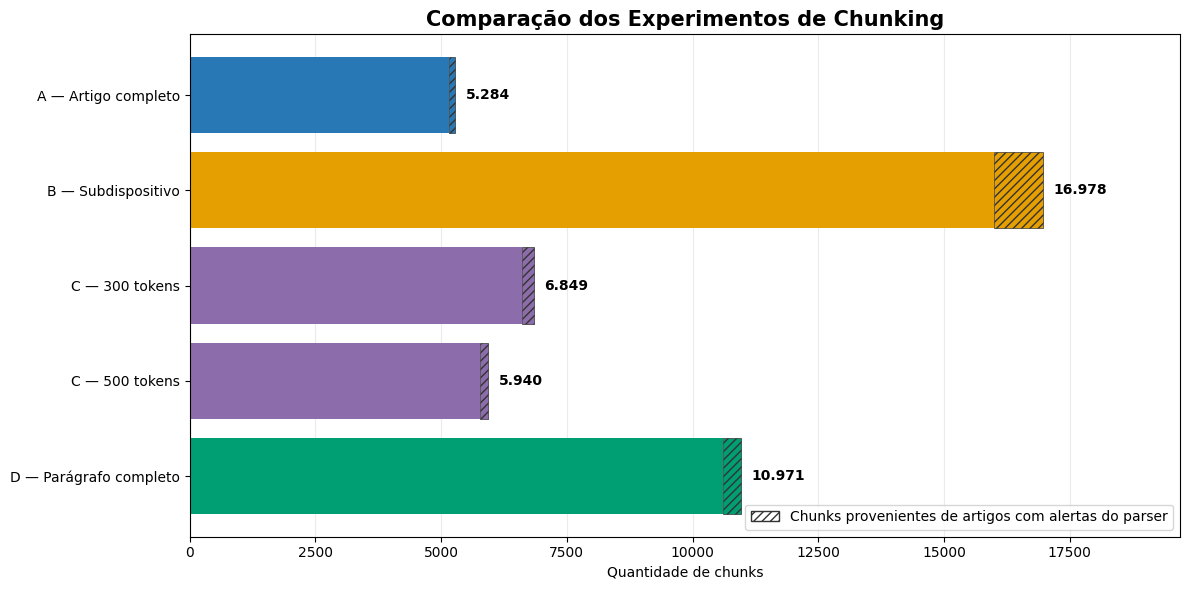

,Estratégia,Chunks,Artigos cobertos,Principal resultado
0,A — Artigo completo,5284,5284,Preserva o artigo inteiro e gera menos chunks.
1,B — Subdispositivo,16978,5284,"Produz trechos menores, mas separa mais os dispositivos de seu contexto."
2,C — 300 tokens,6849,5284,Controla o tamanho do corpo; 98.05% das fronteiras internas cortam intervalos de dispositivos.
3,C — 500 tokens,5940,5284,Controla o tamanho do corpo; 98.17% das fronteiras internas cortam intervalos de dispositivos. A janela de 500 tokens fragmenta menos que a de 300.
4,D — Parágrafo completo,10971,5284,"Oferece granularidade intermediária, mantendo incisos e alíneas com o parágrafo."


• A e D são candidatas prioritárias para comparar na recuperação; ainda não há uma estratégia vencedora.
• Todas as versões cobrem os mesmos artigos. Cobertura textual não garante contexto suficiente em cada chunk.
• Os cortes são medidos contra os intervalos do parser; os alertas de hierarquia continuam pendentes de revisão.
• Quantidade de chunks não mede relevância: a escolha depende da avaliação de recuperação e das citações.


In [18]:
# Comparação final dos experimentos: quantidade de chunks e interpretação estrutural.
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

strategy_descriptions = {
    'A_artigo': (
        'A — Artigo completo',
        'Preserva o artigo inteiro e gera menos chunks.'
    ),
    'B_subdispositivo': (
        'B — Subdispositivo',
        'Produz trechos menores, mas separa mais os dispositivos de seu contexto.'
    ),
    'C_tokens_300_overlap_50': (
        'C — 300 tokens',
        'Controla o tamanho do corpo, porém cerca de 98% das fronteiras internas cortam intervalos de dispositivos.'
    ),
    'C_tokens_500_overlap_75': (
        'C — 500 tokens',
        'Fragmenta menos que a janela de 300, mas mantém cortes dentro dos dispositivos.'
    ),
    'C_caracteres_1200_overlap_200': (
        'C — 1.200 caracteres',
        'Janela de referência em caracteres; controla tamanho, mas pode cortar dispositivos. Não equivale a uma janela em tokens.'
    ),
    'C_caracteres_2000_overlap_300': (
        'C — 2.000 caracteres',
        'Janela maior em caracteres; pode reduzir a fragmentação, mas não respeita necessariamente os dispositivos.'
    ),
    'D_paragrafo_completo': (
        'D — Parágrafo completo',
        'Oferece granularidade intermediária, mantendo incisos e alíneas com o parágrafo.'
    )
}

summary_records = []
for strategy_value, group in df_chunks.groupby('estrategia', sort=True):
    strategy = str(strategy_value)
    label, description = strategy_descriptions.get(strategy, (strategy, 'Consultar a configuração da estratégia.'))
    cuts = df_cortes[df_cortes['estrategia'] == strategy]
    if strategy.startswith('C_') and not cuts.empty:
        cut_rate = cuts['corta_intervalo_dispositivo'].mean() * 100
        description = (
            f"Controla o tamanho do corpo; {cut_rate:.2f}% das fronteiras internas cortam intervalos de dispositivos. "
            + ('A janela de 500 tokens fragmenta menos que a de 300.' if strategy.startswith('C_tokens_500_') else '')
        ).strip()
    summary_records.append({
        'codigo': strategy, 'Estratégia': label, 'Chunks': len(group),
        'Artigos cobertos': group['artigo_id'].nunique(),
        'Principal resultado': description,
        'Chunks de artigos com alertas': int(group['tem_alerta_parser'].sum())
    })

df_comparacao_final = pd.DataFrame(summary_records)
colors = {'A': '#2878B5', 'B': '#E69F00', 'C': '#8D6CAB', 'D': '#009E73'}
fig, ax = plt.subplots(figsize=(12, 6))
positions = range(len(df_comparacao_final))
alert_counts = df_comparacao_final['Chunks de artigos com alertas']
clean_counts = df_comparacao_final['Chunks'] - alert_counts
bar_colors = [colors.get(code[0], '#777777') for code in df_comparacao_final['codigo']]
ax.barh(positions, clean_counts, color=bar_colors)
ax.barh(positions, alert_counts, left=clean_counts, color=bar_colors,
        hatch='////', edgecolor='#333333', linewidth=0.5)
ax.set_yticks(list(positions), labels=df_comparacao_final['Estratégia'])
ax.invert_yaxis()
for index, total in enumerate(df_comparacao_final['Chunks']):
    ax.text(total + df_comparacao_final['Chunks'].max() * 0.012, index,
            f'{total:,}'.replace(',', '.'), va='center', fontweight='bold')
ax.set_xlim(0, df_comparacao_final['Chunks'].max() * 1.16)
ax.set_xlabel('Quantidade de chunks')
ax.set_title('Comparação dos Experimentos de Chunking', fontsize=15, fontweight='bold')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
ax.legend(handles=[Patch(facecolor='white', edgecolor='#333333', hatch='////',
                         label='Chunks provenientes de artigos com alertas do parser')], loc='lower right')
fig.tight_layout()
plt.show()

# As explicações permanecem na mesma linha da estratégia para facilitar a leitura.
with pd.option_context('display.max_colwidth', None):
    display(df_comparacao_final[['Estratégia', 'Chunks', 'Artigos cobertos', 'Principal resultado']])

print('• A e D são candidatas prioritárias para comparar na recuperação; ainda não há uma estratégia vencedora.')
print('• Todas as versões cobrem os mesmos artigos. Cobertura textual não garante contexto suficiente em cada chunk.')
print('• Os cortes são medidos contra os intervalos do parser; os alertas de hierarquia continuam pendentes de revisão.')
print('• Quantidade de chunks não mede relevância: a escolha depende da avaliação de recuperação e das citações.')

REPORT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(REPORT_DIR / 'comparacao_final_experimentos.png', dpi=160, bbox_inches='tight')
df_comparacao_final.to_csv(REPORT_DIR / 'comparacao_final_experimentos.csv', index=False, encoding='utf-8')